# 02 · EDA de Bronze

## 0. Carga y forma de los datos

In [1]:
"""
Profe, aquí cargamos los cuatro objetos de Bronze con las funciones de src/, sin tocar ni un archivo: las edificaciones con su
geometría, el CSV de estrato leído todo como texto, los polígonos de barrios y el metadato de la capa. Lo hicimos con dtype=str en el
CSV porque si dejábamos que pandas adivinara los tipos, los códigos y los números con coma de miles se nos iban a dañar sin darnos
cuenta. La salida muestra la forma de cada tabla, los tipos y el porcentaje de nulos por columna. Lo que esto NO dice es si los
nulos son errores o ausencias legítimas; eso lo vamos discutiendo columna por columna en las secciones siguientes.
"""
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src.extract.extract_api import load_edificaciones_raw, load_json_bronze, load_poligonos_raw
from src.extract.extract_excel import read_csv_raw, latest_csv
from src.transform.keys import codigo_barrio, codigo_csv
pd.set_option('display.width', 200, 'display.max_columns', 30, 'display.max_rows', 80)

e, geoms = load_edificaciones_raw()
csv, enc = read_csv_raw(latest_csv())
meta = load_json_bronze('capa_meta.json')
print('edificaciones:', e.shape, '| CSV estrato:', csv.shape, '| codificación que funcionó:', enc)
nulos = (e.isna().mean() * 100).round(2)
print(pd.DataFrame({'dtype': e.dtypes.astype(str), 'nulos_%': nulos, 'únicos': e.nunique()}))


edificaciones: (5146, 20) | CSV estrato: (369, 10) | codificación que funcionó: utf-8
                      dtype  nulos_%  únicos
OBJECTID              int64     0.00    5146
OBJECTID_1           object   100.00       0
DEPAPRED                str     0.00       2
MUNIPRED                str     0.00       2
TIPO_AVALU              str     4.88       2
SECTOR                  str     0.00       2
COMUNA                  str     0.00       8
BARRIO                  str     0.00      32
MANZANA                 str     0.00      63
TERRENO                 str     0.00     127
COND                    str     0.14       7
EDIFPRED                str    10.96       4
PREDIO                  str     0.00     141
NUMEPRED                str     0.23    1078
NPISOS              float64     0.21      12
ID_PREDIO           float64    29.32     948
Indice_Escombros    float64     8.45    4703
Estado_Estructural      str     0.00       4
Shape__Area         float64     0.00    5052
Shape__Length 

In [2]:
"""
Aquí revisamos el metadato de la capa, que guardamos como archivo de Bronze justamente para tener evidencia de vigencia. Nos fijamos
en la fecha de última edición, en el extent geográfico y en si trae copyright, y comparamos el conteo oficial de la capa antes y después
de descargar contra las filas que realmente bajamos. La salida muestra que coinciden las tres cifras y que el extent es una caja
pequeña dentro de Cali. Lo que NO demuestra es la licencia de uso: copyrightText viene vacío, así que ese dato lo tenemos que
declarar como no disponible en el README y no inventarlo.
"""
import datetime as dt
ult = meta['editingInfo']['lastEditDate'] / 1000
print('última edición de la capa (UTC):', dt.datetime.fromtimestamp(ult, dt.timezone.utc).strftime('%Y-%m-%d %H:%M'))
print('copyrightText:', repr(meta.get('copyrightText')), '| description:', repr(meta.get('description')))
print('extent:', {k: round(v, 4) for k, v in meta['extent'].items() if k != 'spatialReference'})
print('conteo antes / después / filas bajadas:', load_json_bronze('count_antes.json')['count'],
      load_json_bronze('count_despues.json')['count'], len(e))


última edición de la capa (UTC): 2026-09-03 00:24
copyrightText: '' | description: ''
extent: {'xmin': -76.5633, 'ymin': 3.3889, 'xmax': -76.5243, 'ymax': 3.4454}
conteo antes / después / filas bajadas: 5146 5146 5146


## 1. Duplicados, rangos y cardinalidad

In [3]:
"""
En esta celda buscamos duplicados por varias llaves candidatas, porque no sabíamos cuál era la llave natural de una edificación.
Probamos OBJECTID, la combinación catastral completa (comuna, barrio, manzana, terreno, condición, edificio, predio) y la geometría
exacta. Nos dimos cuenta de que OBJECTID es único y por eso lo vamos a usar como identificador de la edificación, mientras que
la llave catastral se repite porque un predio puede tener varias construcciones. La salida también muestra que OBJECTID_1 viene
100 % vacía y que ID_PREDIO trae muchos ceros. Esto no prueba que no haya dobles conteos reales, solo que las geometrías idénticas son pocas.
"""
print('OBJECTID únicos:', e.OBJECTID.is_unique, '| OBJECTID_1 nulos:', e.OBJECTID_1.isna().sum(), 'de', len(e))
llave_cat = ['COMUNA', 'BARRIO', 'MANZANA', 'TERRENO', 'COND', 'EDIFPRED', 'PREDIO']
print('filas con llave catastral repetida (varias construcciones por predio):', e.duplicated(llave_cat, keep=False).sum())
gstr = pd.Series([str(g['rings']) if g else None for g in geoms])
print('geometrías idénticas repetidas:', gstr.duplicated().sum(), '| geometrías nulas:', gstr.isna().sum())
print('ID_PREDIO: nulos', e.ID_PREDIO.isna().sum(), '| ceros', (e.ID_PREDIO == 0).sum())
print('valores en blanco (solo espacios) por columna de texto:')
txt = [c for c in e.columns if not pd.api.types.is_numeric_dtype(e[c]) and e[c].notna().any()]
print({c: int((e[c].astype('string').str.strip() == '').sum()) for c in txt})
print(e[['NPISOS', 'Indice_Escombros']].describe().round(3))
print('Shape__Area (grados², no m²): min/mediana/max =', e.Shape__Area.min(), e.Shape__Area.median(), e.Shape__Area.max())
print('NPISOS == 0:', (e.NPISOS == 0).sum(), '| NPISOS > 8:', (e.NPISOS > 8).sum())


OBJECTID únicos: True | OBJECTID_1 nulos: 5146 de 5146
filas con llave catastral repetida (varias construcciones por predio): 3719
geometrías idénticas repetidas: 9 | geometrías nulas: 0
ID_PREDIO: nulos 1509 | ceros 1697
valores en blanco (solo espacios) por columna de texto:
{'DEPAPRED': 1, 'MUNIPRED': 10, 'TIPO_AVALU': 11, 'SECTOR': 10, 'COMUNA': 2, 'BARRIO': 2, 'MANZANA': 2, 'TERRENO': 1587, 'COND': 190, 'EDIFPRED': 3533, 'PREDIO': 2, 'NUMEPRED': 2896, 'Estado_Estructural': 0}
         NPISOS  Indice_Escombros
count  5135.000          4711.000
mean      1.593            -6.015
std       1.401             8.383
min       0.000           -48.817
25%       1.000           -10.023
50%       2.000            -4.911
75%       2.000            -1.118
max      13.000            35.441
Shape__Area (grados², no m²): min/mediana/max = 2.2737367544323206e-13 5.880167464056285e-09 1.0727286223755073e-06
NPISOS == 0: 1234 | NPISOS > 8: 11


## 2. Problemas de formato del CSV de estrato

In [4]:
"""
Acá inspeccionamos el CSV tal como llegó. Vimos que la primera columna es el código único, que hay un bloque final de filas de
resumen por comuna y una fila Otros con código guion, que los conteos vienen con espacios y guiones en vez de ceros, que hay números
con coma de miles (por ejemplo 2,324) y que el estrato moda trae el valor NR en algunos barrios. También confirmamos la codificación,
porque al verificar las fuentes habíamos supuesto latin-1 y resultó ser UTF-8. La salida cuenta cada problema. Esto no corrige nada, solo documenta
lo que Silver tendrá que resolver con una regla por cada hallazgo.
"""
csv.columns = ['cod', 'barrio'] + [f'lados_e{i}' for i in range(1, 7)] + ['sin_vivienda', 'moda']
raw = latest_csv().read_bytes()
print('UTF-8 válido:', raw.decode('utf-8') is not None, '| BOM:', raw[:3] == b'\xef\xbb\xbf', '| saltos CRLF:', raw.count(b'\r\n'))
cols_n = [f'lados_e{i}' for i in range(1, 7)] + ['sin_vivienda']
patron = lambda s: s.map(lambda v: 'vacío' if v.strip() == '' else ('guion' if v.strip() == '-' else ('miles con coma' if ',' in v else 'número')))
print(pd.concat({c: patron(csv[c]).value_counts() for c in cols_n}, axis=1).fillna(0).astype(int))
filas_resumen = csv[~csv.cod.str.strip().str.fullmatch(r'\d+')]
print('filas resumen (código no numérico):', len(filas_resumen), '| ejemplo:', filas_resumen.barrio.str.strip().head(3).tolist(), '...', filas_resumen.barrio.str.strip().iloc[-1])
print('estrato moda:', csv.moda.str.strip().value_counts().to_dict())
print('espacios sobrantes en barrio:', int((csv.barrio != csv.barrio.str.strip()).sum()), '| dobles espacios internos:', int(csv.barrio.str.contains('  ').sum()))


UTF-8 válido: True | BOM: False | saltos CRLF: 0
                lados_e1  lados_e2  lados_e3  lados_e4  lados_e5  lados_e6  sin_vivienda
guion                230       159       161       244       268       313             3
número               135       206       204       123       101        56           366
miles con coma         3         4         4         1         0         0             0
vacío                  1         0         0         1         0         0             0
filas resumen (código no numérico): 23 | ejemplo: ['Comuna 1', 'Comuna 2', 'Comuna 3'] ... Otros
estrato moda: {'3': 129, '2': 94, '1': 54, '5': 35, '4': 35, '6': 16, 'NR': 6}
espacios sobrantes en barrio: 3 | dobles espacios internos: 23


## 3. Llave del JOIN

In [5]:
"""
Esta sección es la central, profe. La llave que definimos al verificar las fuentes es el código de barrio armado como entero de comuna por 100 más
barrio, escrito como texto sin ceros a la izquierda, por ejemplo comuna 19 y barrio 04 dan 1904. Lo hicimos así porque las
edificaciones no traen el nombre del barrio, solo los dos códigos catastrales de dos dígitos, y el CSV sí trae un código único.
Verificamos que la llave sea única en el lado del CSV y vemos cuántas edificaciones no encuentran pareja y por qué. La salida muestra
que casi todo cruza; no demuestra que el código catastral y el código del CSV signifiquen exactamente el mismo barrio, eso lo
contrastamos después con los polígonos.
"""
csv['cod_n'] = csv.cod.map(codigo_csv)
barrios = csv[csv.cod_n.notna()].copy()
e['cod'] = [codigo_barrio(c, b) for c, b in zip(e.COMUNA, e.BARRIO)]
print('barrios en el CSV:', len(barrios), '| códigos únicos:', barrios.cod_n.is_unique, '| nombres repetidos:', int(barrios.barrio.str.strip().duplicated().sum()))
print('edificaciones con llave construible:', e.cod.notna().sum(), '| sin llave (COMUNA o BARRIO en blanco):', e.cod.isna().sum())
e['llave_ok'] = e.cod.isin(set(barrios.cod_n))
print('cobertura de llave:', round(e.llave_ok.mean() * 100, 2), '%  (', int(e.llave_ok.sum()), 'de', len(e), ')')
sin = e[~e.llave_ok]
print(sin.assign(COMUNA=sin.COMUNA.str.strip().replace('', 'vacío')).groupby(['COMUNA', 'BARRIO'], dropna=False).size().rename('edificaciones'))
print('códigos de barrio distintos en edificaciones:', e.cod.nunique())


barrios en el CSV: 346 | códigos únicos: True | nombres repetidos: 0
edificaciones con llave construible: 5144 | sin llave (COMUNA o BARRIO en blanco): 2
cobertura de llave: 99.88 %  ( 5140 de 5146 )
COMUNA  BARRIO
19      20        4
vacío             2
Name: edificaciones, dtype: int64
códigos de barrio distintos en edificaciones: 52


## 4. Dos coberturas: llave y estrato válido

In [6]:
"""
Aquí separamos dos coberturas que no son lo mismo, y esto nos parece clave para no engañarnos. La primera es la de la llave, o sea
si la edificación encuentra su barrio en el CSV. La segunda es la de estrato válido, o sea que además ese barrio tenga un estrato moda
entre 1 y 6, porque NR, los guiones y las filas de comuna o de Otros no sirven para el análisis. Contamos cuántas edificaciones caen
en barrios NR. La salida muestra que la segunda cobertura es un poco menor que la primera. Lo que no dice es si el estrato moda
representa bien a un barrio heterogéneo, eso lo vemos en la sección de pureza del estrato.
"""
barrios['moda_n'] = pd.to_numeric(barrios.moda.str.strip(), errors='coerce')
m = e.merge(barrios[['cod_n', 'barrio', 'moda', 'moda_n']], left_on='cod', right_on='cod_n', how='left')
m['estrato'] = m.moda_n.where(m.moda_n.between(1, 6))
print('cobertura llave:', round(m.cod_n.notna().mean() * 100, 3), '% | cobertura estrato válido (1-6):', round(m.estrato.notna().mean() * 100, 3), '%')
print('edificaciones en barrios con moda NR:', int((m.moda.str.strip() == 'NR').sum()), '| barrios NR con edificaciones:', m[m.moda.str.strip() == 'NR'].cod.nunique())
print(m[m.moda.str.strip() == 'NR'][['cod', 'barrio']].drop_duplicates())
print('edificaciones sin estrato válido en total:', int(m.estrato.isna().sum()), '(sin llave:', int((~e.llave_ok).sum()), '+ NR:', int((m.moda.str.strip() == 'NR').sum()), ')')
print('barrios del CSV con estrato válido y edificaciones:', m.dropna(subset=['estrato']).cod.nunique(), 'de', len(barrios))


cobertura llave: 99.883 % | cobertura estrato válido (1-6): 99.845 %
edificaciones en barrios con moda NR: 2 | barrios NR con edificaciones: 1
       cod                            barrio
2505  1999  U. Dep. A. Galindo   Plaza Toros


edificaciones sin estrato válido en total: 8 (sin llave: 6 + NR: 2 )
barrios del CSV con estrato válido y edificaciones: 50 de 346


## 5. Estado_Estructural e Indice_Escombros

{'sin_cambio': 3357, 'techo': 1058, 'sin_datos': 435, 'escombros': 296}
            count     min  median     max
clase                                    
escombros     296   4.347   7.816  35.441
sin_cambio   3357 -10.799  -3.739   4.297
sin_datos       0     NaN     NaN     NaN
techo        1058 -48.817 -15.432 -10.800
Indice_Escombros nulo: 435 | de ellos en sin_datos: 435


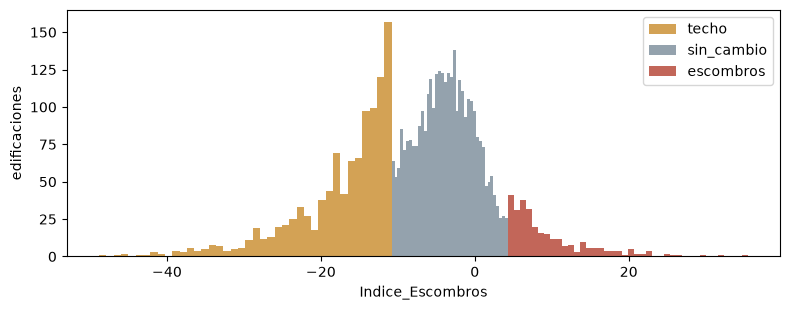

In [7]:
"""
Ahora miramos la variable de daño. Estado_Estructural tiene cuatro clases y Indice_Escombros es un número continuo, y queríamos
saber cómo se relacionan. Calculamos mínimo, mediana y máximo del índice por clase y dibujamos el histograma. Nos dimos cuenta de que
las clases son cortes del índice (escombros por encima de unos 4,3, techo por debajo de unos menos 10,8) y de que Sin datos
satelitales es exactamente la clase donde el índice está vacío. Por eso proponemos que Sin datos salga del denominador y se reporte
aparte, nunca como sin daño. Esto no demuestra que el índice mida daño real, solo que es coherente con las clases.
"""
def clase(s):
    return ('escombros' if s.startswith('Alta') else 'techo' if s.startswith('Posible') else
            'sin_cambio' if s.startswith('Sin cambio') else 'sin_datos' if s.startswith('Sin datos') else 'otra')
m['clase'] = m.Estado_Estructural.map(clase)
print(m.clase.value_counts().to_dict())
print(m.groupby('clase').Indice_Escombros.agg(['count', 'min', 'median', 'max']).round(3))
print('Indice_Escombros nulo:', int(m.Indice_Escombros.isna().sum()), '| de ellos en sin_datos:', int(m[m.Indice_Escombros.isna()].clase.eq('sin_datos').sum()))
fig, ax = plt.subplots(figsize=(8, 3.2))
for c, col in [('techo', '#c98b2a'), ('sin_cambio', '#7a8b99'), ('escombros', '#b3402f')]:
    ax.hist(m[m.clase == c].Indice_Escombros, bins=40, alpha=.8, label=c, color=col)
ax.set_xlabel('Indice_Escombros'); ax.set_ylabel('edificaciones'); ax.legend(); plt.tight_layout(); plt.show()


In [8]:
"""
Aquí fijamos, de forma provisional, las dos banderas que proponemos para la etapa Silver. Severo estricto es solo la clase de alta probabilidad de
escombros, y daño visible suma escombros más posible desaparición de techo. Lo hicimos con dos banderas porque no sabemos todavía
cuál tiene más sentido y preferimos mostrar ambas. Calculamos las tasas con el denominador sin la clase Sin datos satelitales y
reportamos aparte cuántas edificaciones quedan fuera. La salida muestra el tamaño de cada grupo. Esto no confirma el umbral, que sigue
provisional hasta la etapa Silver, y tampoco dice que daño visible sea daño estructural.
"""
m['severo_estricto'] = m.clase.eq('escombros')
m['dano_visible'] = m.clase.isin(['escombros', 'techo'])
con_datos = m[m.clase != 'sin_datos']
print('con datos satelitales (denominador):', len(con_datos), '| sin datos (fuera, aparte):', int((m.clase == 'sin_datos').sum()))
print('severo_estricto:', int(con_datos.severo_estricto.sum()), '=', round(con_datos.severo_estricto.mean() * 100, 2), '% del denominador')
print('dano_visible   :', int(con_datos.dano_visible.sum()), '=', round(con_datos.dano_visible.mean() * 100, 2), '% del denominador')


con datos satelitales (denominador): 4711 | sin datos (fuera, aparte): 435
severo_estricto: 296 = 6.28 % del denominador
dano_visible   : 1354 = 28.74 % del denominador


## 6. Distribución por comuna, barrio y estrato

In [9]:
"""
En esta celda cruzamos las clases contra comuna, barrio y estrato, incluyendo la clase Sin datos satelitales, porque queríamos saber
si esa falta de datos se concentra en alguna zona o estrato, lo cual sesgaría las tasas. Contamos edificaciones y severos por estrato y
marcamos los estratos con menos de 30 severos, que es el mínimo que nos pusimos para no leer porcentajes sobre muy pocos casos.
La salida muestra tablas por comuna y por estrato. Lo que NO muestra es una relación causal: solo cuántos edificios hay en cada
grupo, y el estrato 6 casi no tiene edificaciones en esta muestra.
"""
com = m.COMUNA.str.strip().replace('', 'vacío')
print(pd.crosstab(com, m.clase, margins=True))
print((pd.crosstab(com, m.clase, normalize='index') * 100).round(1)['sin_datos'].rename('% sin_datos por comuna'))
est = (m.dropna(subset=['estrato']).groupby('estrato')
       .agg(n=('OBJECTID', 'size'), sin_datos=('clase', lambda s: (s == 'sin_datos').sum()),
            severos=('severo_estricto', 'sum'), dano_visible=('dano_visible', 'sum')))
est['n_con_datos'] = est.n - est.sin_datos
est['%_sin_datos'] = (est.sin_datos / est.n * 100).round(1)
est['%_severo'] = (est.severos / est.n_con_datos * 100).round(2)
est['%_dano_visible'] = (est.dano_visible / est.n_con_datos * 100).round(2)
est['alerta_<30_severos'] = est.severos < 30
print(est)
top = m.groupby('cod').agg(barrio=('barrio', 'first'), n=('OBJECTID', 'size'), severos=('severo_estricto', 'sum')).sort_values('n', ascending=False)
print('barrios con edificaciones:', len(top), '| con >=10 edificaciones:', int((top.n >= 10).sum()))
print(top.head(8))


clase   escombros  sin_cambio  sin_datos  techo   All
COMUNA                                               
03             39         378         61    133   611
09              7         124         18     53   202
10             35         398         36    108   577
17              4          63         12     20    99
18              8          72         17     16   113
19            182        2075        232    652  3141
20             20         247         59     75   401
vacío           1           0          0      1     2
All           296        3357        435   1058  5146
COMUNA
03       10.0
09        8.9
10        6.2
17       12.1
18       15.0
19        7.4
20       14.7
vacío     0.0
Name: % sin_datos por comuna, dtype: float64
            n  sin_datos  severos  dano_visible  n_con_datos  %_sin_datos  %_severo  %_dano_visible  alerta_<30_severos
estrato                                                                                                                
1.

## 7. Coherencia de la llave con los polígonos

In [10]:
"""
Como bajamos los polígonos de barrios en Bronze, los usamos solo para validar la llave, no para hacer el JOIN. Tomamos el centroide
de cada edificación, buscamos en qué polígono cae con shapely y comparamos el código del polígono con el código que derivamos de
comuna y barrio. Lo hicimos porque queríamos saber si el código catastral realmente ubica a la edificación en el barrio correcto.
La salida da el porcentaje que coincide y los pares de códigos que no, que son sobre todo recodificaciones entre el esquema de 2015 y
el de 2026. Esto no demuestra cuál de los dos códigos es el correcto para el estrato; solo mide cuánto se parecen.
"""
from shapely.geometry import shape, Polygon
from shapely.strtree import STRtree
poly = load_poligonos_raw()
pg = [shape(f['geometry']) for f in poly['features']]
pk = [str(int(f['properties']['barcodigo'])) for f in poly['features']]
tree = STRtree(pg)
def poligono_de(g):
    idx = tree.query(Polygon(g['rings'][0]).centroid, predicate='within')
    return pk[idx[0]] if len(idx) else None
m['cod_poligono'] = [poligono_de(g) for g in geoms]
print('polígonos:', len(pg), '| códigos únicos:', len(set(pk)), '| edificaciones sin polígono:', int(m.cod_poligono.isna().sum()))
con = m.cod.notna()
coincide = (m.cod == m.cod_poligono)
print('coincidencia código derivado vs polígono:', round(coincide[con].mean() * 100, 2), '% | edificaciones que difieren:', int((~coincide[con]).sum()))
dif = m[con & ~coincide].groupby(['cod', 'cod_poligono']).size().sort_values(ascending=False).rename('edificaciones')
print(dif.head(8))
print('las edificaciones sin pareja en el CSV, según el polígono donde caen:')
print(m[m.cod_n.isna()].groupby([m.COMUNA.str.strip().replace('', 'vacío'), m.BARRIO.str.strip().replace('', 'vacío'), 'cod_poligono'], dropna=False).size())
por_cod = coincide[con].groupby(m.cod).mean()
print('códigos de edificaciones con coincidencia total:', int((por_cod == 1).sum()), 'de', len(por_cod), '| con coincidencia 0:', int((por_cod == 0).sum()))
print('códigos de polígono (2026) presentes en el CSV de 2015:', round(np.mean([k in set(barrios.cod_n) for k in pk]) * 100, 1), '%')


polígonos: 342 | códigos únicos: 342 | edificaciones sin polígono: 0
coincidencia código derivado vs polígono: 91.43 % | edificaciones que difieren: 441
cod   cod_poligono
1994  1931            198
1890  1817             60
1778  1708             48
1785  1714             42
1984  1927             30
1988  1929             18
2098  2010             16
1983  1926             11
Name: edificaciones, dtype: int64
las edificaciones sin pareja en el CSV, según el polígono donde caen:
COMUNA  BARRIO  cod_poligono
19      20      1933            4
vacío   vacío   1913            1
                2001            1
dtype: int64
códigos de edificaciones con coincidencia total: 39 de 52 | con coincidencia 0: 13
códigos de polígono (2026) presentes en el CSV de 2015: 73.4 %


## 8. Pureza del estrato por barrio

In [11]:
"""
Aquí medimos qué tan homogéneo es el estrato dentro de cada barrio. Con las columnas de lados de manzana por estrato calculamos el
porcentaje de lados que están en el estrato moda; si es 100 % el barrio es puro, y si es bajo el barrio mezcla estratos. Lo hicimos
porque asignar a cada edificación el estrato moda de su barrio es una aproximación y queríamos saber qué tan mala es. Para esto
tuvimos que convertir los textos con guion y coma de miles a números, solo en memoria y sin tocar Bronze. La salida cuenta
cuántos barrios con edificaciones son heterogéneos; no mide la pureza a nivel de la edificación individual, que es la falacia ecológica.
"""
def a_numero(s):
    return pd.to_numeric(s.str.replace(',', '').str.strip().replace('-', np.nan), errors='coerce')
L = pd.concat([a_numero(barrios[f'lados_e{i}']) for i in range(1, 7)], axis=1).fillna(0)
L.columns = range(1, 7)
barrios['lados_total'] = L.sum(axis=1)
barrios['pureza'] = L.max(axis=1) / barrios.lados_total.replace(0, np.nan)
barrios['argmax_estrato'] = L.idxmax(axis=1).where(barrios.lados_total > 0)
valido = barrios[barrios.moda_n.notna() & (barrios.lados_total > 0)]
print('pureza (mediana / p25 / mínimo):', valido.pureza.median().round(3), valido.pureza.quantile(.25).round(3), valido.pureza.min().round(3))
print('estrato moda == estrato con más lados:', round((valido.argmax_estrato == valido.moda_n).mean() * 100, 1), '%')
print('barrios con lados_total = 0:', int((barrios.lados_total == 0).sum()))
b_con = barrios.merge(m.groupby('cod').size().rename('n_edif'), left_on='cod_n', right_index=True)
print('barrios con edificaciones:', len(b_con), '| pureza < 0.8:', int((b_con.pureza < .8).sum()), '| pureza < 0.6:', int((b_con.pureza < .6).sum()))
ponder = (b_con.pureza * b_con.n_edif).sum() / b_con.dropna(subset=['pureza']).n_edif.sum()
print('pureza media ponderada por edificaciones:', round(ponder, 3))
print(b_con[b_con.pureza < .6][['cod_n', 'barrio', 'pureza', 'n_edif']].round(2))


pureza (mediana / p25 / mínimo): 0.955 0.765 0.333
estrato moda == estrato con más lados: 100.0 %
barrios con lados_total = 0: 3
barrios con edificaciones: 51 | pureza < 0.8: 18 | pureza < 0.6: 5
pureza media ponderada por edificaciones: 0.872
    cod_n                        barrio  pureza  n_edif
276  1903                       El Lido    0.59     235
281  1908                  Santa Isabel    0.54     174
283  1910            San Fernando Viejo    0.46      88
294  1922   Camino Real   J. Borrero S.    0.56      71
295  1923  Camino Real   Los Fundadores    0.47      62


## 9. Cobertura geográfica

In [12]:
"""
Para cerrar la parte de datos revisamos qué comunas aparecen realmente en la capa de edificaciones. Las que esperábamos eran la 19, la
03, la 10, la 20, la 09, la 18 y la 17, y nos interesaba confirmar que la Comuna 2 no está, porque varios de los barrios que mencionó
el Avance 1 como golpeados están ahí. La salida lista las comunas con su número de edificaciones y de barrios. Esto confirma que la
muestra es un subconjunto de la ciudad por construcción de la fuente, y por eso ningún resultado se puede leer como prevalencia
de Cali entera.
"""
presentes = m.assign(com=com).groupby('com').agg(edificaciones=('OBJECTID', 'size'), barrios=('cod', 'nunique'))
print(presentes)
esperadas = {'03', '09', '10', '17', '18', '19', '20'}
print('comunas presentes:', sorted(set(presentes.index) - {'vacío'}), '| coinciden con las esperadas:', set(presentes.index) - {'vacío'} == esperadas)
print('Comuna 2 presente:', '02' in presentes.index, '| comunas del CSV sin ninguna edificación:', 22 - len(esperadas))


       edificaciones  barrios
com                          
03               611        3
09               202        2
10               577        8
17                99        4
18               113        5
19              3141       25
20               401        5
vacío              2        0
comunas presentes: ['03', '09', '10', '17', '18', '19', '20'] | coinciden con las esperadas: True
Comuna 2 presente: False | comunas del CSV sin ninguna edificación: 15


## 10. Alcance del proxy

In [13]:
"""
Profe, queremos dejar explícito qué mide y qué no mide la variable de daño, para que nadie la lea de más. Estado_Estructural viene de
comparar la textura de una imagen satelital de marzo con otra del 11 de agosto sobre la huella de cada edificio, entonces mide un cambio
visible desde arriba, como un techo que desapareció o escombros. No mide daño interno, fisuras, daño en cimientos ni, si no
me equivoco, edificios de varios pisos que sufrieron daño sin cambio visible en el techo. Además solo hay edificaciones dentro de
polígonos de afectación preliminar. La celda resume la tasa de Sin cambio aparente por número de pisos, solo como señal de ese
límite, sin concluir nada.
"""
pisos = m[m.clase != 'sin_datos'].assign(grupo=lambda d: pd.cut(d.NPISOS, [-1, 1, 2, 4, 20], labels=['0-1', '2', '3-4', '5+']))
print(pisos.groupby('grupo', observed=True).agg(n=('OBJECTID', 'size'), pct_dano_visible=('dano_visible', lambda s: round(s.mean() * 100, 1)),
                                                 pct_severo=('severo_estricto', lambda s: round(s.mean() * 100, 1))))
print('Estado_Estructural describe: cambio visible desde satélite (textura pre/post); NO daño interno ni cimientos; NO verificación ATC-20.')


          n  pct_dano_visible  pct_severo
grupo                                    
0-1    2308              29.4         6.5
2      1559              27.8         6.0
3-4     681              29.2         6.9
5+      156              26.9         4.5
Estado_Estructural describe: cambio visible desde satélite (textura pre/post); NO daño interno ni cimientos; NO verificación ATC-20.


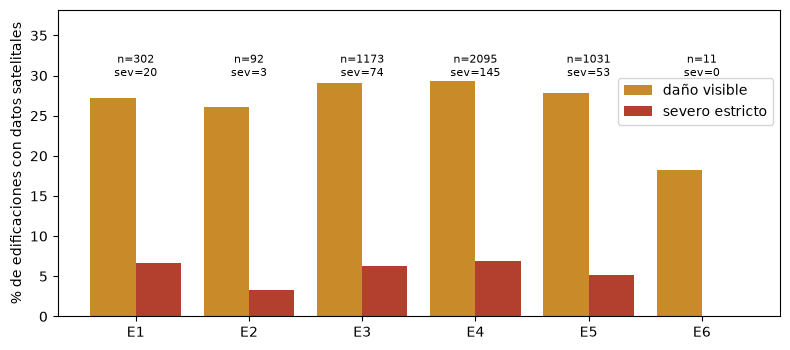

In [14]:
"""
Cerramos con el gráfico que resume el EDA: el porcentaje de edificaciones con daño visible y con severo estricto por estrato, con el
número de edificaciones de cada barra anotado. Lo hicimos para que la figura no se pueda leer sin ver el tamaño de muestra, porque los
estratos 1, 2 y 6 tienen muy pocos casos severos y por eso sus tasas son inestables. La salida es la figura. No demuestra que el
estrato cambie la probabilidad de daño: es una descripción de la muestra, con sesgo de selección por polígonos de afectación y con el
estrato asignado por barrio, así que cualquier diferencia podría explicarse por dónde se ubican los edificios.
"""
fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(len(est))
ax.bar(x - .2, est['%_dano_visible'], .4, label='daño visible', color='#c98b2a')
ax.bar(x + .2, est['%_severo'], .4, label='severo estricto', color='#b3402f')
for i, (n, sv) in enumerate(zip(est.n_con_datos, est.severos)):
    ax.text(i, max(est['%_dano_visible'].max(), 1) * 1.02, f'n={n}\nsev={sv}', ha='center', fontsize=8)
ax.set_xticks(x); ax.set_xticklabels([f'E{int(i)}' for i in est.index]); ax.set_ylabel('% de edificaciones con datos satelitales')
ax.set_ylim(0, est['%_dano_visible'].max() * 1.3); ax.legend(loc='upper right', bbox_to_anchor=(1, .8)); plt.tight_layout(); plt.show()
